Pour avoir les plot avec une police différente, plus proche de celle qu'on utilise en LaTeX.

In [1]:
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'DejaVu Serif'  # ou 'DejaVu Sans' ou 'DejaVu Sans Mono'

# Lecture des données

## Datasets OMNI

In [2]:
# voir data_access_download.py pour les conventions de nom de fichier

import pickle

#SC22
with open('C:/Users/pierr/OneDrive - IPSA/Documents/IPSA/Aero 5/PMI/data/omni_speasycda2_1h_19840101_19951231.pkl', 'rb') as file:
    omni_speasycda2_1h_19840101_19951231 = pickle.load(file)

#SC23   
with open('C:/Users/pierr/OneDrive - IPSA/Documents/IPSA/Aero 5/PMI/data/omni_speasycda2_1h_19960101_20071231.pkl', 'rb') as file:
    omni_speasycda2_1h_19960101_20071231 = pickle.load(file)

#SC24
with open('C:/Users/pierr/OneDrive - IPSA/Documents/IPSA/Aero 5/PMI/data/omni_speasycda2_1h_20080101_20191231.pkl', 'rb') as file:
    omni_speasycda2_1h_20080101_20191231 = pickle.load(file)

del file

Concatenation

In [3]:
import pandas as pd

#SC22,23,24
omni_speasycda2_1h_19840101_20191231 = pd.concat([
    omni_speasycda2_1h_19840101_19951231,
    omni_speasycda2_1h_19960101_20071231,
    omni_speasycda2_1h_20080101_20191231
]).sort_index()

#SC23,24
omni_speasycda2_1h_19960101_20191231 = pd.concat([
    omni_speasycda2_1h_19960101_20071231,
    omni_speasycda2_1h_20080101_20191231
]).sort_index()

## Carved & Masks

Après carving.py et export

### V1 (distribution SC22 sur SC23)

In [4]:
with open('C:/Users/pierr/OneDrive - IPSA/Documents/IPSA/Aero 5/PMI/data/carvedv1_omni_speasycda2_1h_19960101_20071231.pkl', 'rb') as file:
    carvedv1_omni_speasycda2_1h_19960101_20071231 = pickle.load(file)

with open('C:/Users/pierr/OneDrive - IPSA/Documents/IPSA/Aero 5/PMI/data/maskint_carvedv1_omni_speasycda2_1h_19960101_20071231.pkl', 'rb') as file:
    maskint_carvedv1_omni_speasycda2_1h_19960101_20071231 = pickle.load(file)

del file

### V2 (distribution SC23 sur SC24)

In [5]:
with open('C:/Users/pierr/OneDrive - IPSA/Documents/IPSA/Aero 5/PMI/data/carvedv2_omni_speasycda2_1h_20080101_20191231.pkl', 'rb') as file:
    carvedv2_omni_speasycda2_1h_20080101_20191231 = pickle.load(file)

with open('C:/Users/pierr/OneDrive - IPSA/Documents/IPSA/Aero 5/PMI/data/maskint_carvedv2_omni_speasycda2_1h_20080101_20191231.pkl', 'rb') as file:
    maskint_carvedv2_omni_speasycda2_1h_20080101_20191231 = pickle.load(file)

del file

# Création des matrices mask, timelag, stat

In [6]:
import pandas as pd
from dataset_analysis_functions import compute_mask, compute_stat, compute_timelag

c:\Users\pierr\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\_param_validation.py:14: UserWarning: A NumPy version >=1.23.5 and <2.5.0 is required for this version of SciPy (detected version 2.5.2)
  from scipy.sparse import csr_matrix, issparse


### 1984-1995

In [7]:
#en 1ère position c'est sous format np.array
#en 2nde c'est sous format pd.dataframe

M = compute_mask(omni_speasycda2_1h_19840101_19951231) #mask (np.array)
M_omni_speasycda2_1h_19840101_19951231 = pd.DataFrame(M, columns=omni_speasycda2_1h_19840101_19951231.columns) #mask (pd.df)
_, S_omni_speasycda2_1h_19840101_19951231 = compute_stat(omni_speasycda2_1h_19840101_19951231) #stat (np.array, pd.df)
_, T_omni_speasycda2_1h_19840101_19951231 = compute_timelag(omni_speasycda2_1h_19840101_19951231) #timelag (np.array, pd.df)

### 1996-2007

In [8]:
#en 1ère position c'est sous format np.array
#en 2nde c'est sous format pd.dataframe

M = compute_mask(omni_speasycda2_1h_19960101_20071231) #mask (np.array)
M_omni_speasycda2_1h_19960101_20071231 = pd.DataFrame(M, columns=omni_speasycda2_1h_19960101_20071231.columns) #mask (pd.df)
_, S_omni_speasycda2_1h_19960101_20071231 = compute_stat(omni_speasycda2_1h_19960101_20071231) #stat (np.array, pd.df)
_, T_omni_speasycda2_1h_19960101_20071231 = compute_timelag(omni_speasycda2_1h_19960101_20071231) #timelag (np.array, pd.df)

 ### 1984 - 2019

In [9]:
M = compute_mask(omni_speasycda2_1h_19840101_20191231) #mask (np.array)
M_omni_speasycda2_1h_19840101_20191231 = pd.DataFrame(M, columns=omni_speasycda2_1h_19840101_20191231.columns) #mask (pd.df)
_, S_omni_speasycda2_1h_19840101_20191231 = compute_stat(omni_speasycda2_1h_19840101_20191231, seuil = 70) #stat (np.array, pd.df)
_, T_omni_speasycda2_1h_19840101_20191231 = compute_timelag(omni_speasycda2_1h_19840101_20191231) #timelag (np.array, pd.df)

# Analyse des données manquantes

## Heatmap

In [10]:
from dataset_analysis_functions import heatmap_missing_values, heatmap_mask, heatmap_stat_matrix

### 1984-1995

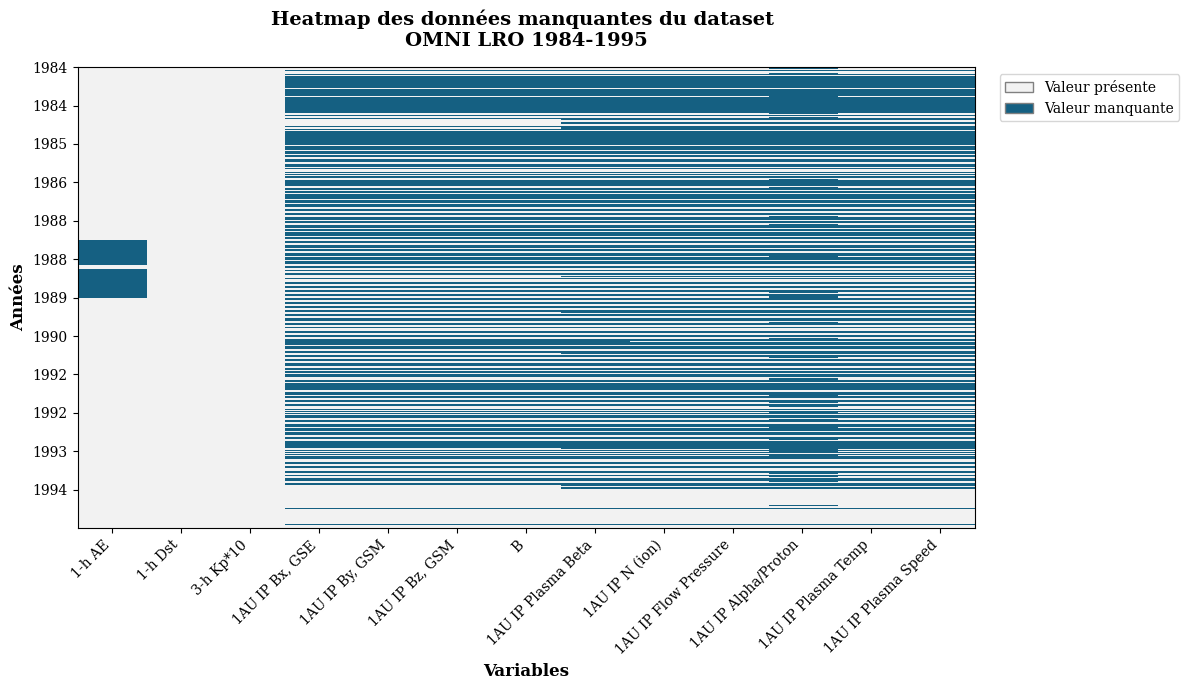

In [33]:
heatmap_missing_values(omni_speasycda2_1h_19840101_19951231[['1-h AE', 
                                                            '1-h Dst', 
                                                            '3-h Kp*10', 
                                                            '1AU IP Bx, GSE', 
                                                            '1AU IP By, GSM', 
                                                            '1AU IP Bz, GSM', 
                                                            'B',
                                                            '1AU IP Plasma Beta', 
                                                            '1AU IP N (ion)', 
                                                            '1AU IP Flow Pressure', 
                                                            '1AU IP Alpha/Proton', 
                                                            '1AU IP Plasma Temp', 
                                                            '1AU IP Plasma Speed']], 
                        df_name = 'OMNI LRO 1984-1995', 
                        cmap_ = [ '#f2f2f2', "#156082"])

### 1996-2007

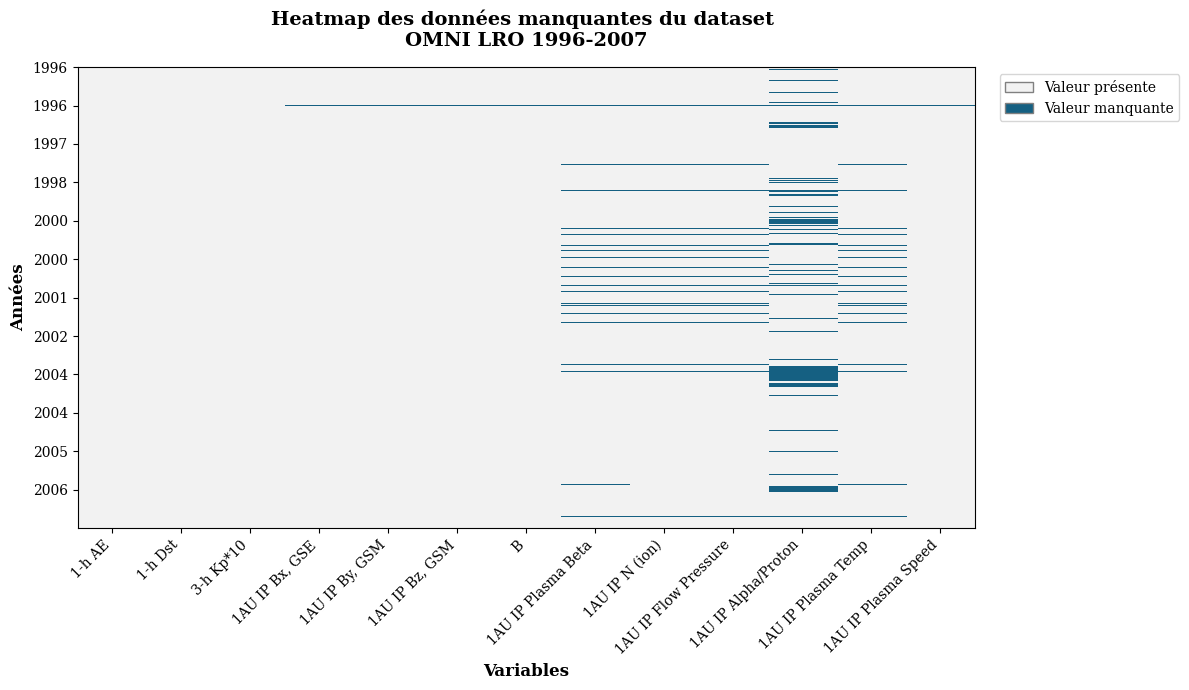

In [29]:
heatmap_missing_values(omni_speasycda2_1h_19960101_20071231[['1-h AE', 
                                                            '1-h Dst', 
                                                            '3-h Kp*10', 
                                                            '1AU IP Bx, GSE', 
                                                            '1AU IP By, GSM', 
                                                            '1AU IP Bz, GSM', 
                                                            'B',
                                                            '1AU IP Plasma Beta', 
                                                            '1AU IP N (ion)', 
                                                            '1AU IP Flow Pressure', 
                                                            '1AU IP Alpha/Proton', 
                                                            '1AU IP Plasma Temp', 
                                                            '1AU IP Plasma Speed']], df_name = 'OMNI LRO 1996-2007', 
                       cmap_ = [ "#f2f2f2", "#156082"])

### 2008-2019

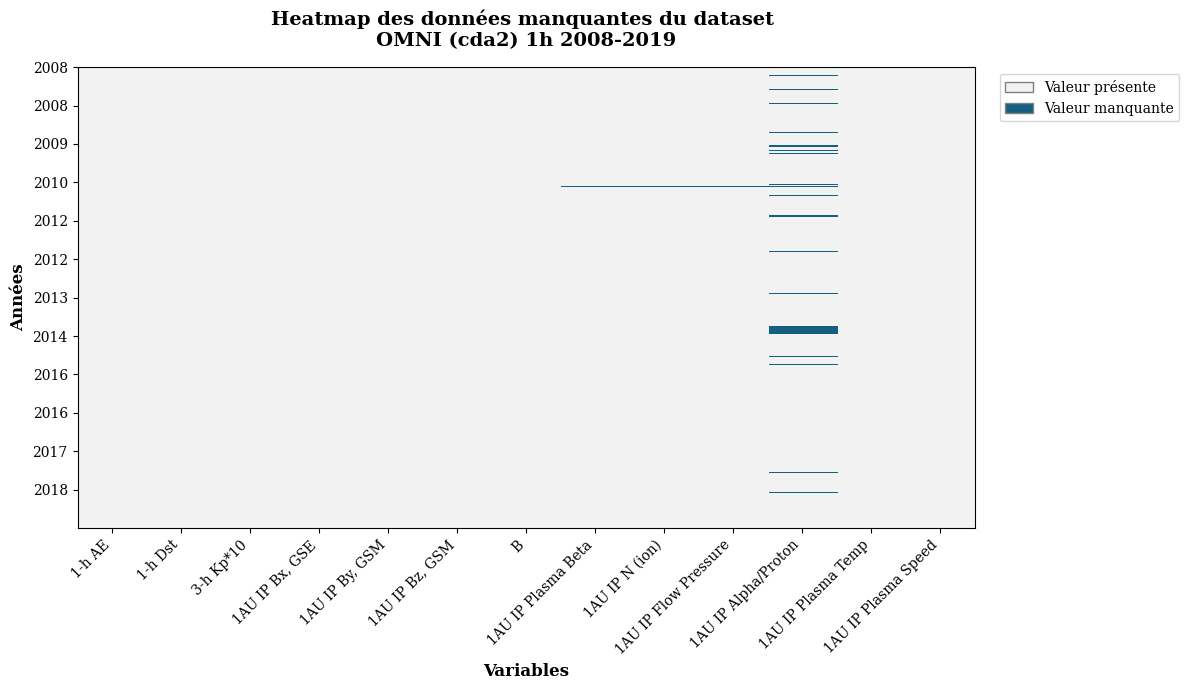

In [32]:
heatmap_missing_values(omni_speasycda2_1h_20080101_20191231[['1-h AE', 
                                                            '1-h Dst', 
                                                            '3-h Kp*10', 
                                                            '1AU IP Bx, GSE', 
                                                            '1AU IP By, GSM', 
                                                            '1AU IP Bz, GSM', 
                                                            'B',
                                                            '1AU IP Plasma Beta', 
                                                            '1AU IP N (ion)', 
                                                            '1AU IP Flow Pressure', 
                                                            '1AU IP Alpha/Proton', 
                                                            '1AU IP Plasma Temp', 
                                                            '1AU IP Plasma Speed']], df_name = 'OMNI (cda2) 1h 2008-2019', 
                       cmap_ = [ '#f2f2f2', "#156082"])

### 1984 - 2019

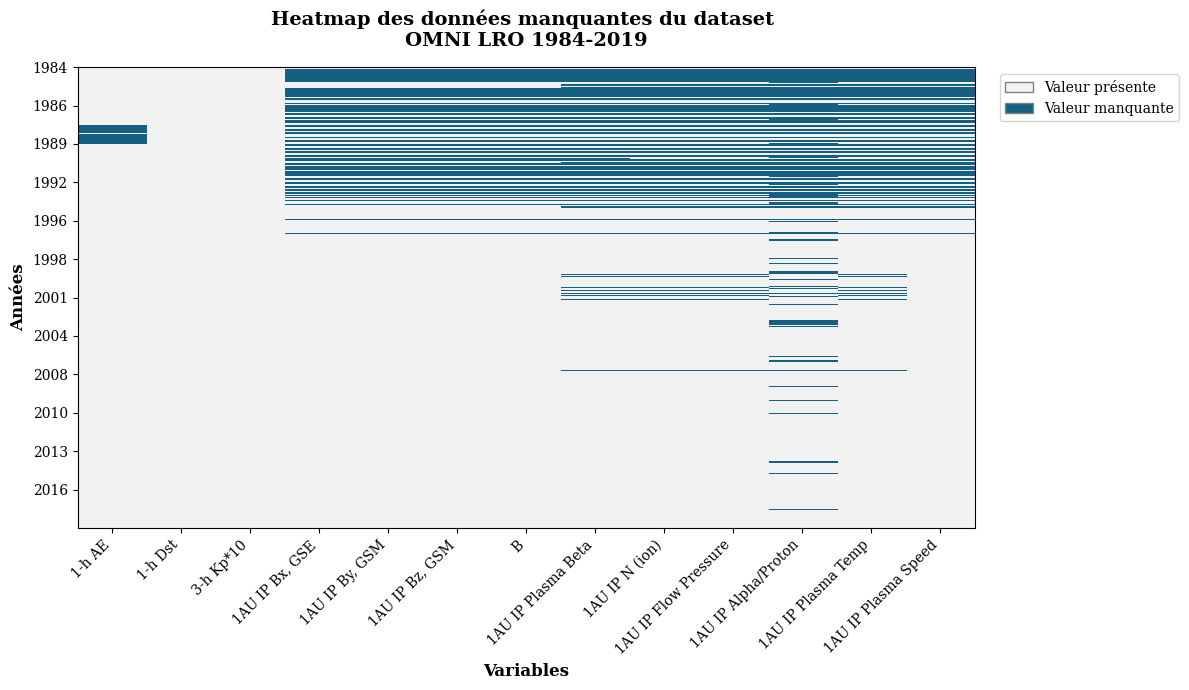

In [31]:
heatmap_missing_values(omni_speasycda2_1h_19840101_20191231[['1-h AE', 
                                                            '1-h Dst', 
                                                            '3-h Kp*10', 
                                                            '1AU IP Bx, GSE', 
                                                            '1AU IP By, GSM', 
                                                            '1AU IP Bz, GSM', 
                                                            'B',
                                                            '1AU IP Plasma Beta', 
                                                            '1AU IP N (ion)', 
                                                            '1AU IP Flow Pressure', 
                                                            '1AU IP Alpha/Proton', 
                                                            '1AU IP Plasma Temp', 
                                                            '1AU IP Plasma Speed']], df_name = 'OMNI LRO 1984-2019', 
                       cmap_ = [ '#f2f2f2', "#156082"])

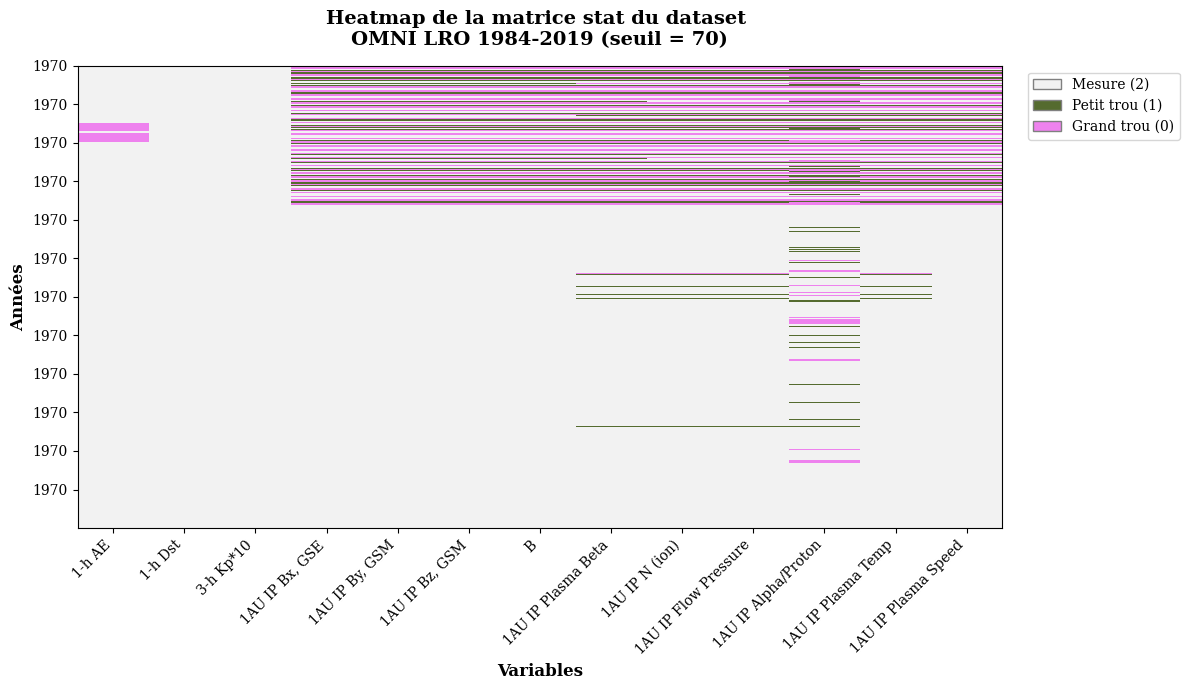

In [35]:
heatmap_stat_matrix(S_omni_speasycda2_1h_19840101_20191231[['1-h AE', 
                                                            '1-h Dst', 
                                                            '3-h Kp*10', 
                                                            '1AU IP Bx, GSE', 
                                                            '1AU IP By, GSM', 
                                                            '1AU IP Bz, GSM', 
                                                            'B',
                                                            '1AU IP Plasma Beta', 
                                                            '1AU IP N (ion)', 
                                                            '1AU IP Flow Pressure', 
                                                            '1AU IP Alpha/Proton', 
                                                            '1AU IP Plasma Temp', 
                                                            '1AU IP Plasma Speed']], df_name='OMNI LRO 1984-2019 (seuil = 70)', 
                                                            cmap_=['violet', "darkolivegreen", '#f2f2f2'])

### Carved

V1

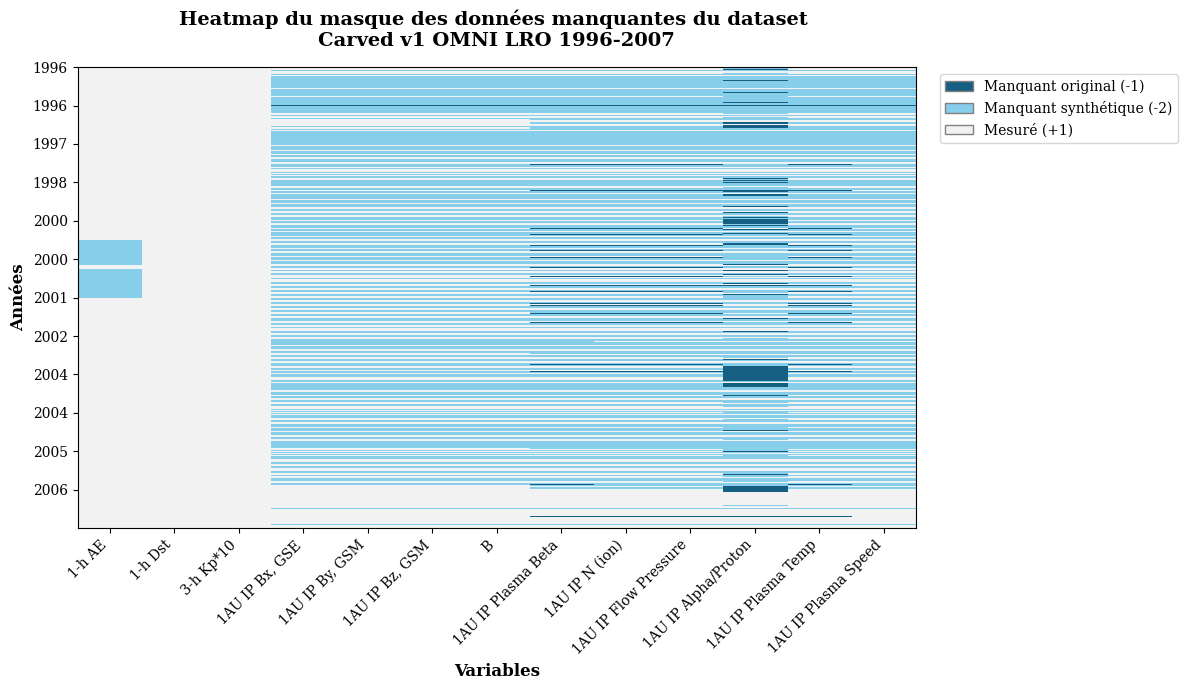

In [16]:
heatmap_mask(maskint_carvedv1_omni_speasycda2_1h_19960101_20071231[['1-h AE', 
                                                            '1-h Dst', 
                                                            '3-h Kp*10', 
                                                            '1AU IP Bx, GSE', 
                                                            '1AU IP By, GSM', 
                                                            '1AU IP Bz, GSM', 
                                                            'B',
                                                            '1AU IP Plasma Beta', 
                                                            '1AU IP N (ion)', 
                                                            '1AU IP Flow Pressure', 
                                                            '1AU IP Alpha/Proton', 
                                                            '1AU IP Plasma Temp', 
                                                            '1AU IP Plasma Speed']],
                                                              df_name='Carved v1 OMNI LRO 1996-2007', 
                                                              cmap_= ['#87ceeb', "#156082", '#f2f2f2'])

V2

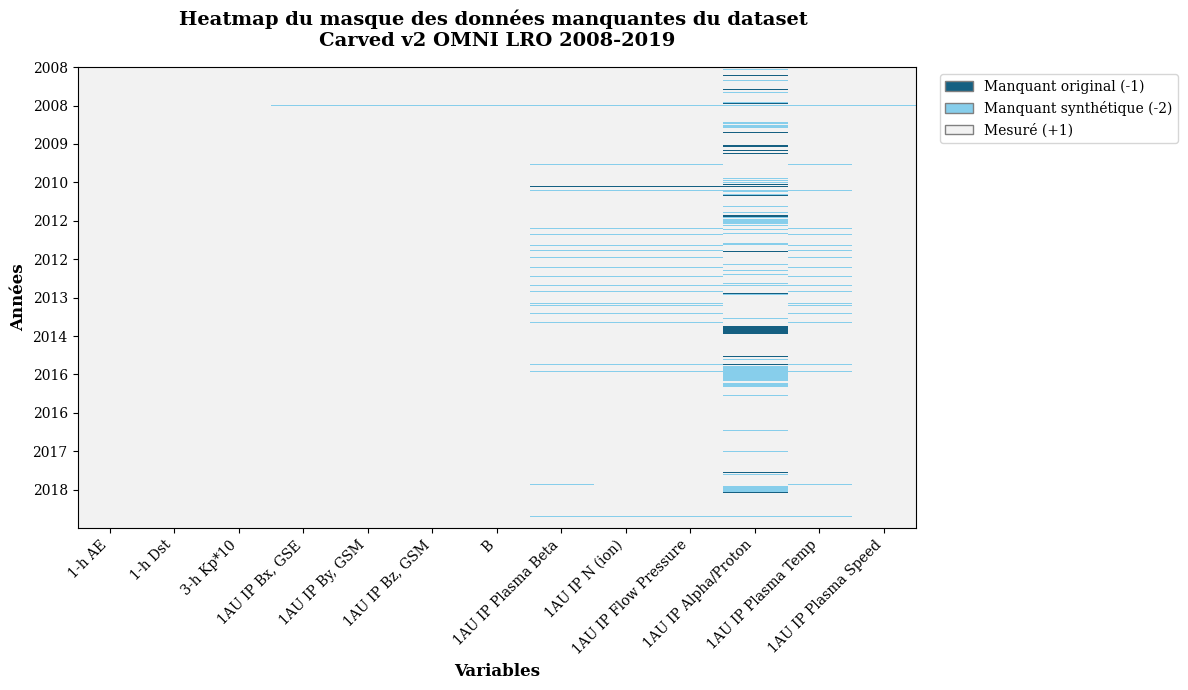

In [17]:
heatmap_mask(maskint_carvedv2_omni_speasycda2_1h_20080101_20191231[['1-h AE', 
                                                            '1-h Dst', 
                                                            '3-h Kp*10', 
                                                            '1AU IP Bx, GSE', 
                                                            '1AU IP By, GSM', 
                                                            '1AU IP Bz, GSM', 
                                                            'B',
                                                            '1AU IP Plasma Beta', 
                                                            '1AU IP N (ion)', 
                                                            '1AU IP Flow Pressure', 
                                                            '1AU IP Alpha/Proton', 
                                                            '1AU IP Plasma Temp', 
                                                            '1AU IP Plasma Speed']],
                                                              df_name='Carved v2 OMNI LRO 2008-2019', 
                                                              cmap_= ['#87ceeb', "#156082", '#f2f2f2'])

## Statistiques

In [18]:
from dataset_analysis_functions import stats_missing_values

### 1984-1995

In [19]:
stats_mv_df = stats_missing_values(M_omni_speasycda2_1h_19840101_19951231)
stats_mv_df

,Nb données manquantes,Pourcentage données manquantes,Nb trous,Moyenne taille trou,Mediane taille trou,Écart-type taille trou
variable,,,,,,
1-h AE,12432,11.818389,2,6216.000000,6216.0,384.000000
"1AU IP Bx, GSE",56663,53.866264,3728,15.199303,4.5,31.823097
"1AU IP By, GSM",56663,53.866264,3728,15.199303,4.5,31.823097
"1AU IP Bz, GSM",56663,53.866264,3728,15.199303,4.5,31.823097
1AU IP Plasma Beta,60418,57.435927,3934,15.357905,4.0,33.658608
1-h Dst,0,0.000000,0,0.000000,0.0,0.000000
3-h Kp*10,0,0.000000,0,0.000000,0.0,0.000000
1AU IP N (ion),59377,56.446308,3819,15.547787,4.0,33.749381
1AU IP Flow Pressure,59377,56.446308,3819,15.547787,4.0,33.749381


### 1996-2007

In [20]:
stats_mv_df = stats_missing_values(M_omni_speasycda2_1h_19960101_20071231)
stats_mv_df

,Nb données manquantes,Pourcentage données manquantes,Nb trous,Moyenne taille trou,Mediane taille trou,Écart-type taille trou
variable,,,,,,
1-h AE,0,0.000000,0,0.000000,0.0,0.000000
"1AU IP Bx, GSE",270,0.256674,47,5.744681,2.0,9.733618
"1AU IP By, GSM",270,0.256674,47,5.744681,2.0,9.733618
"1AU IP Bz, GSM",270,0.256674,47,5.744681,2.0,9.733618
1AU IP Plasma Beta,4355,4.140049,357,12.198880,4.0,17.881252
1-h Dst,0,0.000000,0,0.000000,0.0,0.000000
3-h Kp*10,0,0.000000,0,0.000000,0.0,0.000000
1AU IP N (ion),4318,4.104875,336,12.851190,5.0,18.186416
1AU IP Flow Pressure,4318,4.104875,336,12.851190,5.0,18.186416


### 1996 - 2019

In [21]:
M = compute_mask(omni_speasycda2_1h_19960101_20191231) #mask (np.array)
M_omni_speasycda2_1h_19960101_20191231 = pd.DataFrame(M, columns=omni_speasycda2_1h_19960101_20191231.columns) #mask (pd.df)

stats_mv_df = stats_missing_values(M_omni_speasycda2_1h_19960101_20191231)
stats_mv_df



,Nb données manquantes,Pourcentage données manquantes,Nb trous,Moyenne taille trou,Mediane taille trou,Écart-type taille trou
variable,,,,,,
1-h AE,0,0.000000,0,0.000000,0.0,0.000000
"1AU IP Bx, GSE",277,0.131664,49,5.653061,2.0,9.556600
"1AU IP By, GSM",303,0.144022,50,6.060000,2.0,9.708574
"1AU IP Bz, GSM",303,0.144022,50,6.060000,2.0,9.708574
1AU IP Plasma Beta,5205,2.474047,490,10.622449,3.0,16.223890
1-h Dst,0,0.000000,0,0.000000,0.0,0.000000
3-h Kp*10,0,0.000000,0,0.000000,0.0,0.000000
1AU IP N (ion),5126,2.436497,440,11.650000,4.0,16.764417
1AU IP Flow Pressure,5134,2.440300,444,11.563063,4.0,16.713890


## Histogrammes Valeurs Manquantes

In [22]:
from dataset_analysis_functions import histo_missing_values, histo_multi_missing_values

### 1984-1995

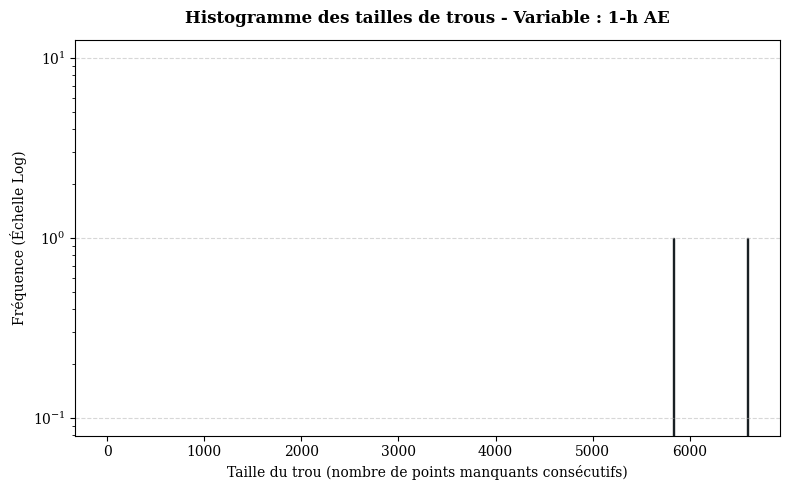

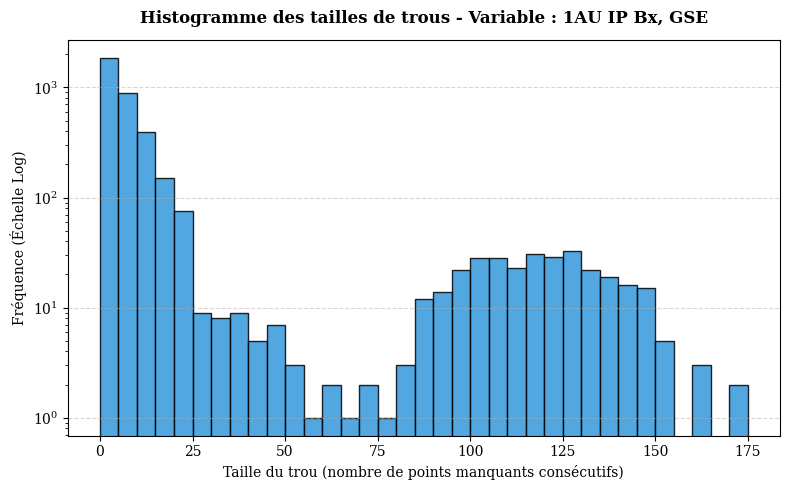

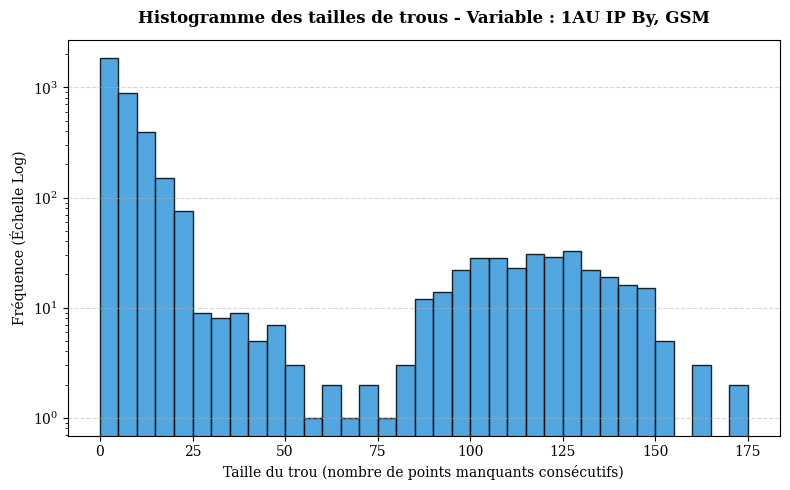

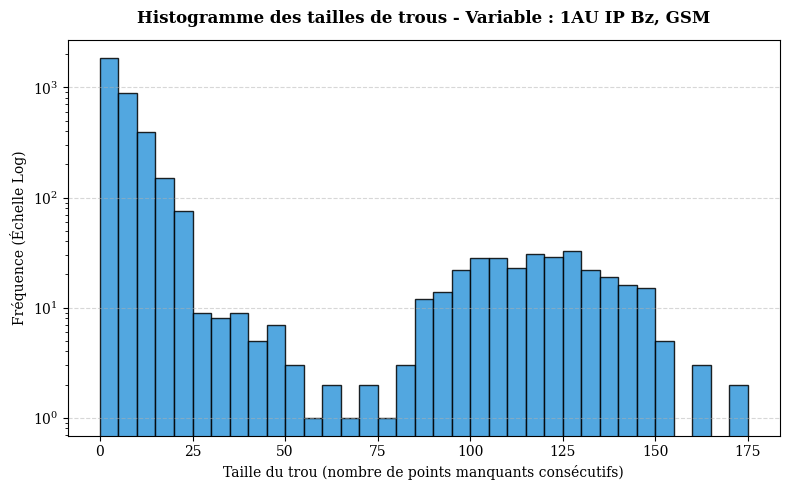

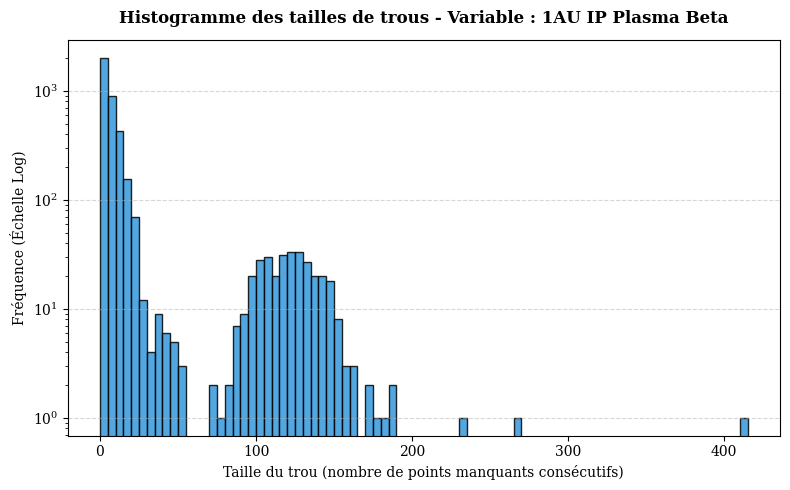

[1-h Dst] Aucune donnée manquante, histogramme ignoré.
[3-h Kp*10] Aucune donnée manquante, histogramme ignoré.


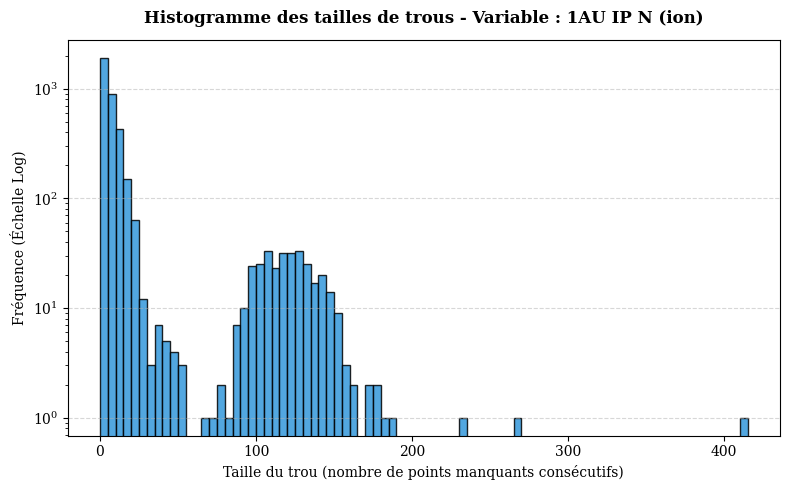

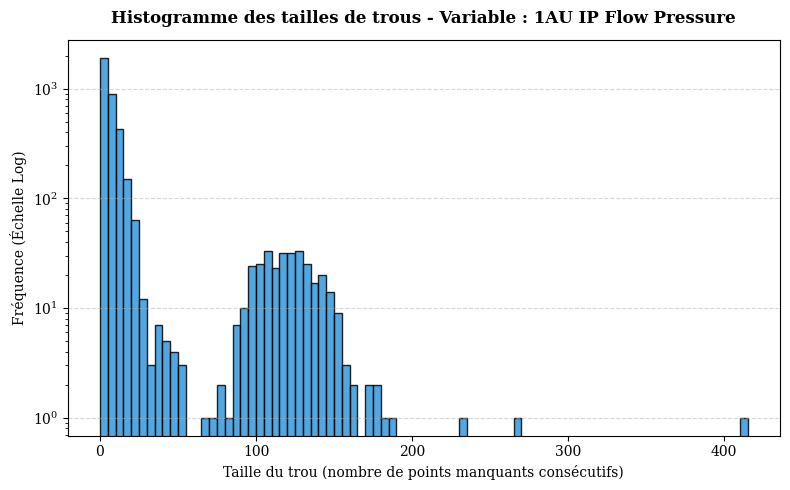

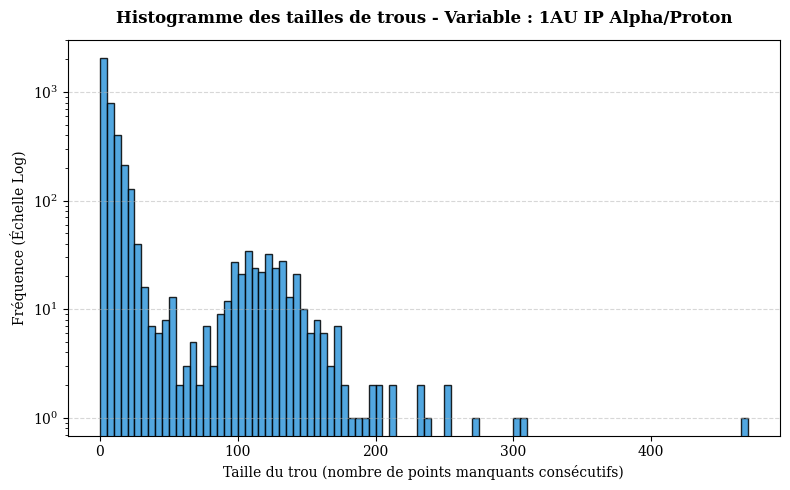

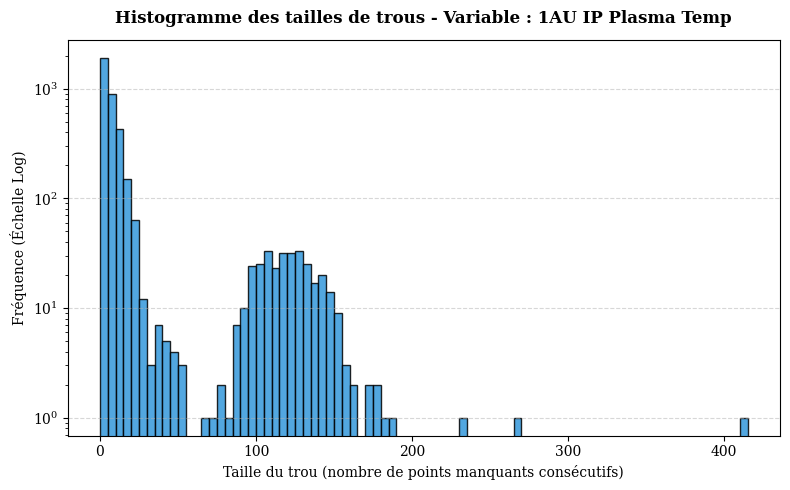

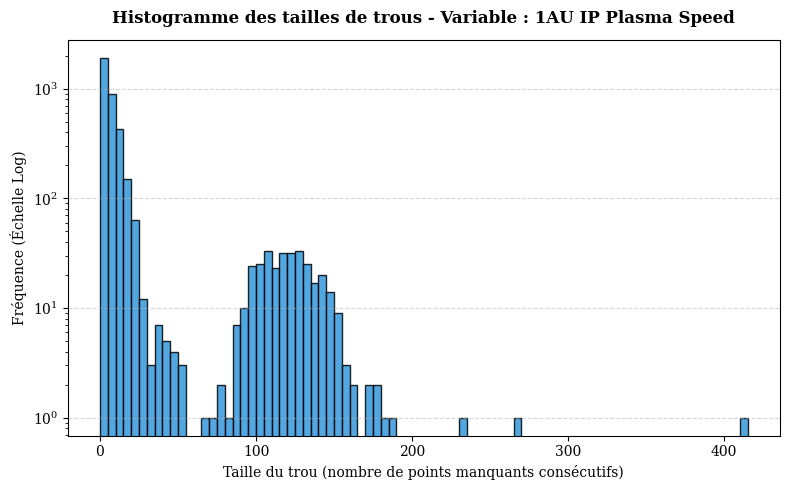

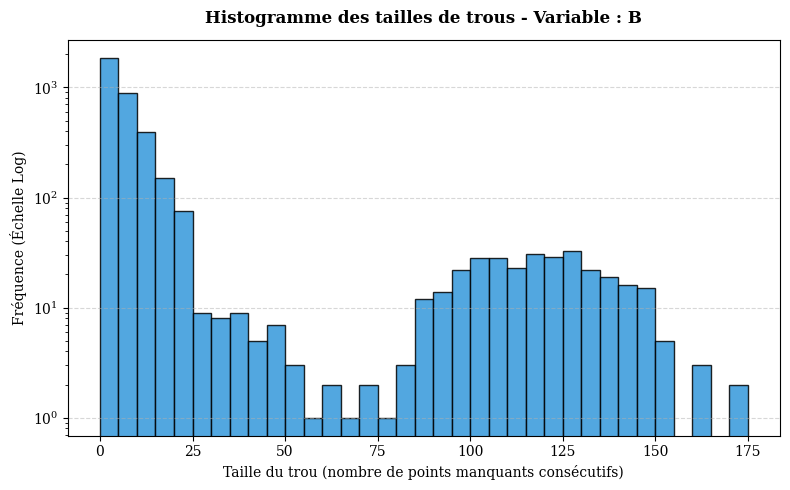

In [23]:
histo_missing_values(M_omni_speasycda2_1h_19840101_19951231)

### 1996-2007

[1-h AE] Aucune donnée manquante, histogramme ignoré.


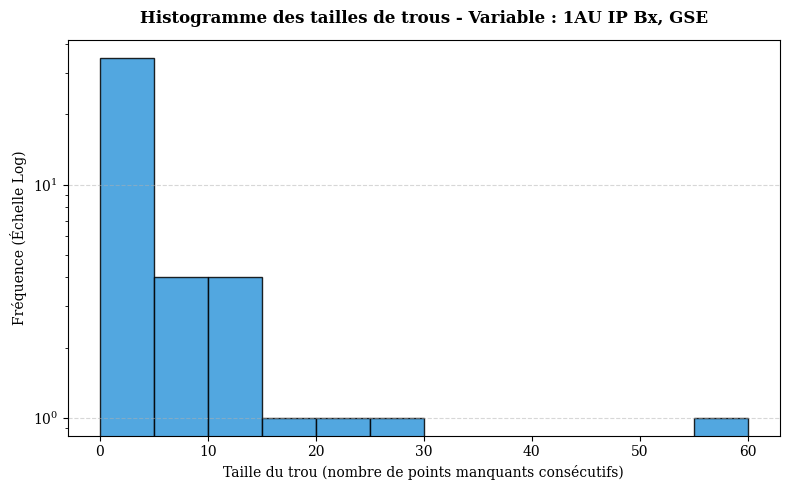

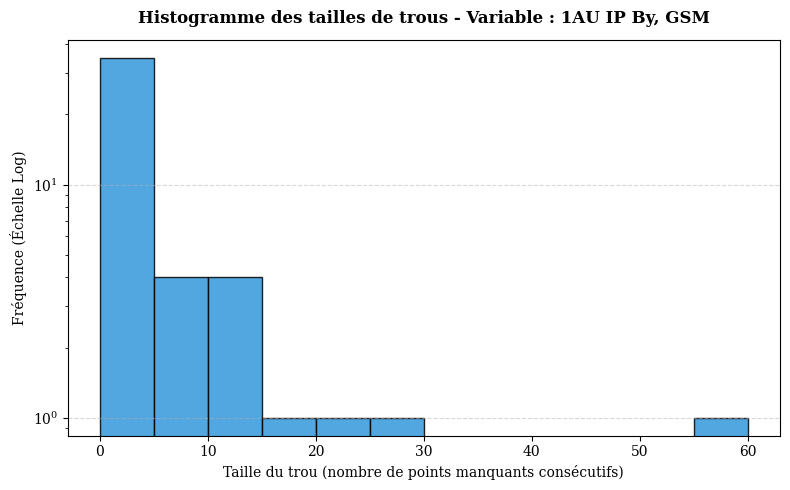

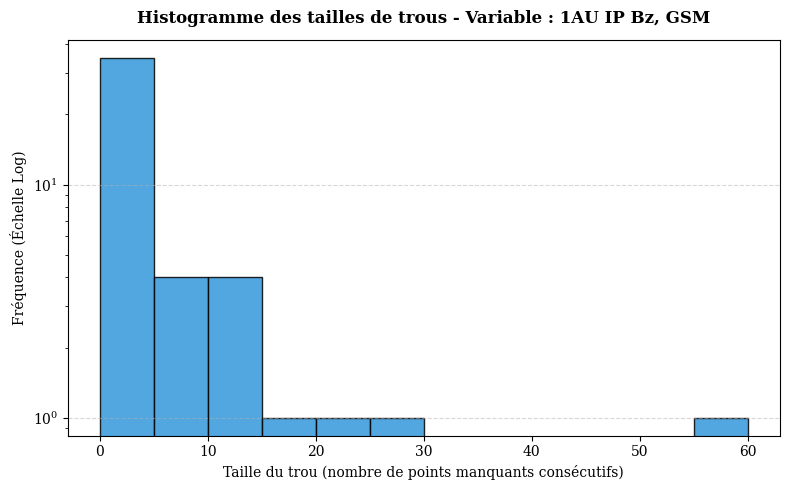

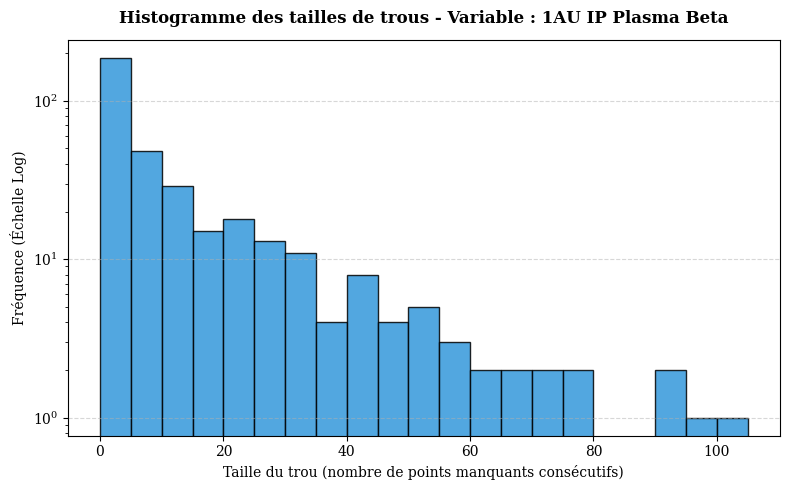

[1-h Dst] Aucune donnée manquante, histogramme ignoré.
[3-h Kp*10] Aucune donnée manquante, histogramme ignoré.


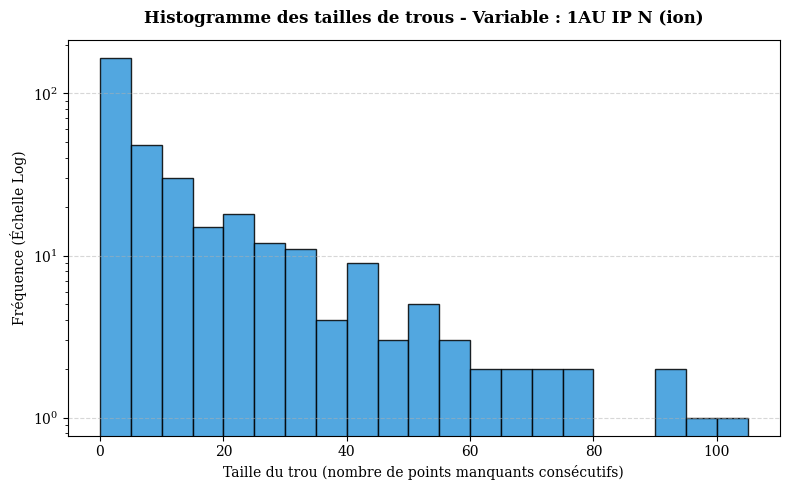

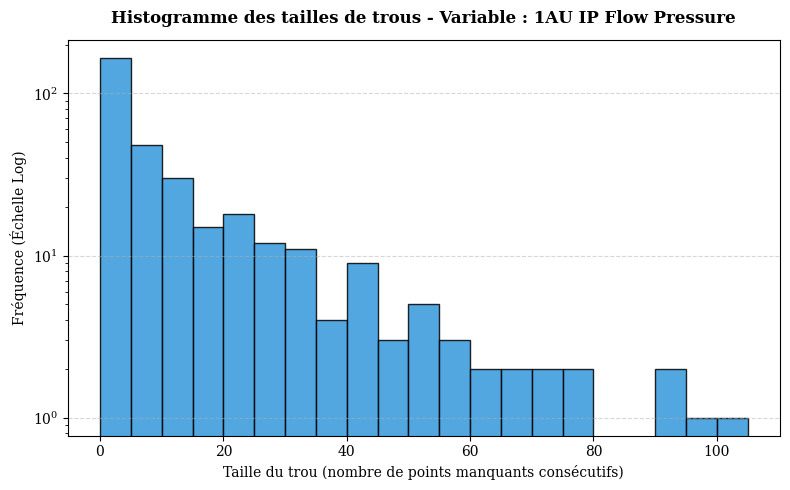

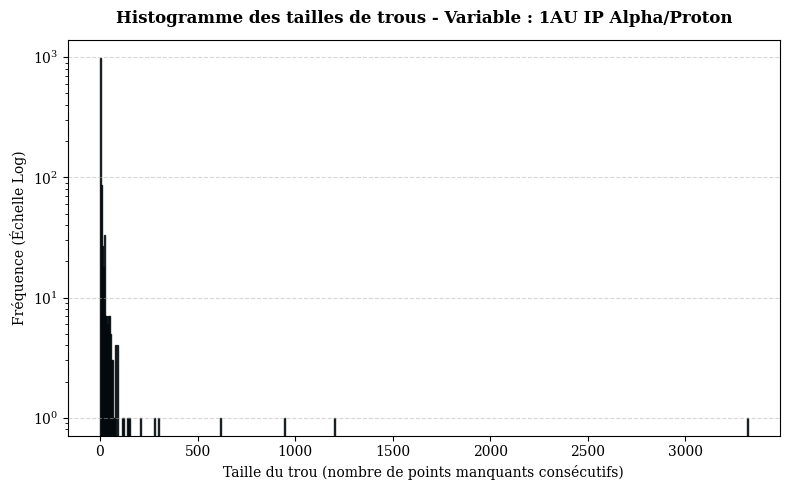

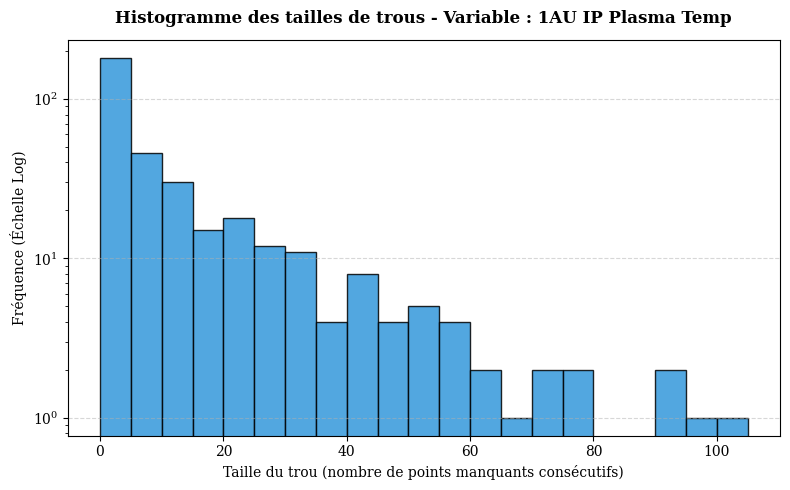

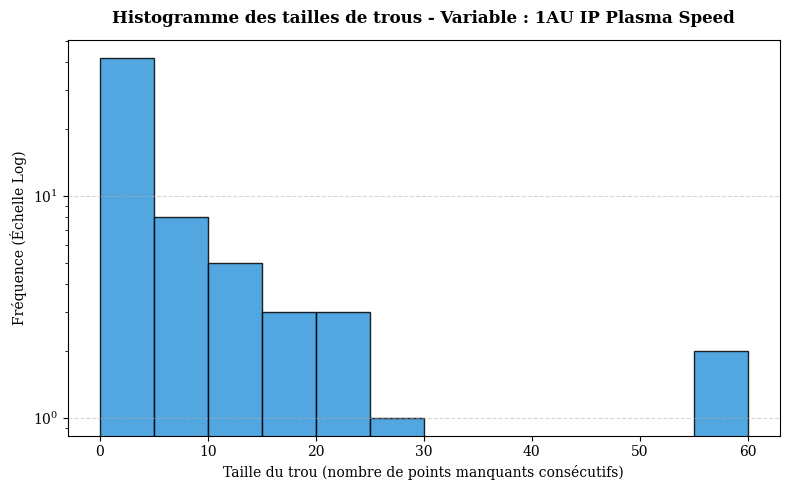

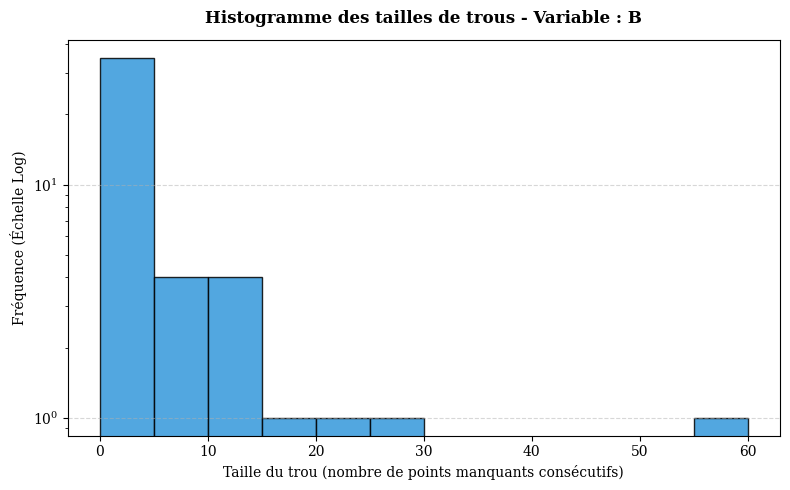

In [24]:
histo_missing_values(M_omni_speasycda2_1h_19960101_20071231)

### Multi (1984-2019)

[1-h Dst] Aucune donnée manquante, histogramme ignoré.


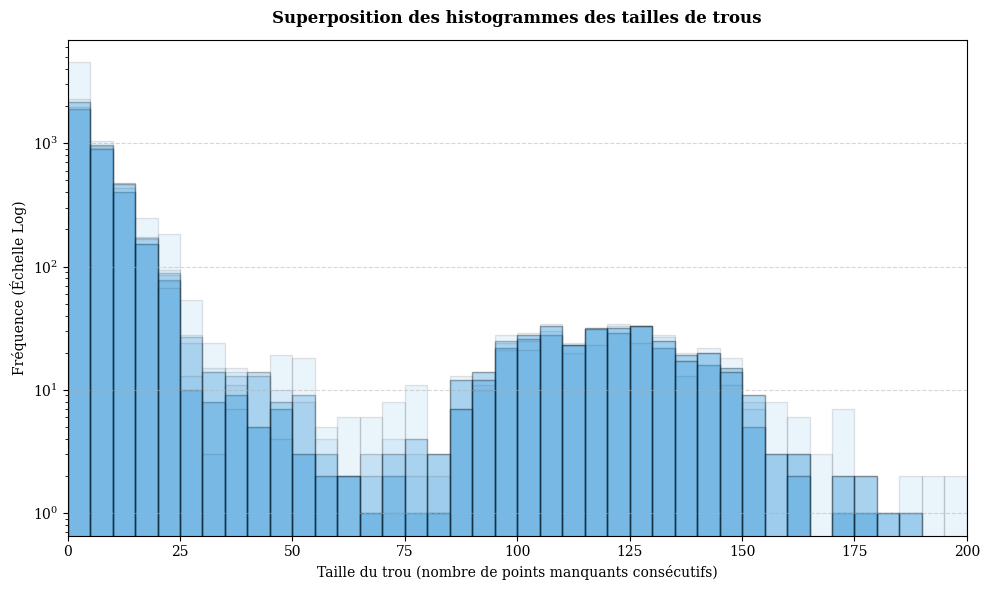

In [25]:
histo_multi_missing_values(M_omni_speasycda2_1h_19840101_20191231[['1-h Dst', 
                                                            '1AU IP Bx, GSE', 
                                                            '1AU IP By, GSM', 
                                                            '1AU IP Bz, GSM', 
                                                            'B',
                                                            '1AU IP Plasma Beta', 
                                                            '1AU IP N (ion)', 
                                                            '1AU IP Flow Pressure', 
                                                            '1AU IP Alpha/Proton', 
                                                            '1AU IP Plasma Temp', 
                                                            '1AU IP Plasma Speed']], )

## Matrice de corrélation

In [26]:
from dataset_analysis_functions import matrice_correlation

### 1984-1995

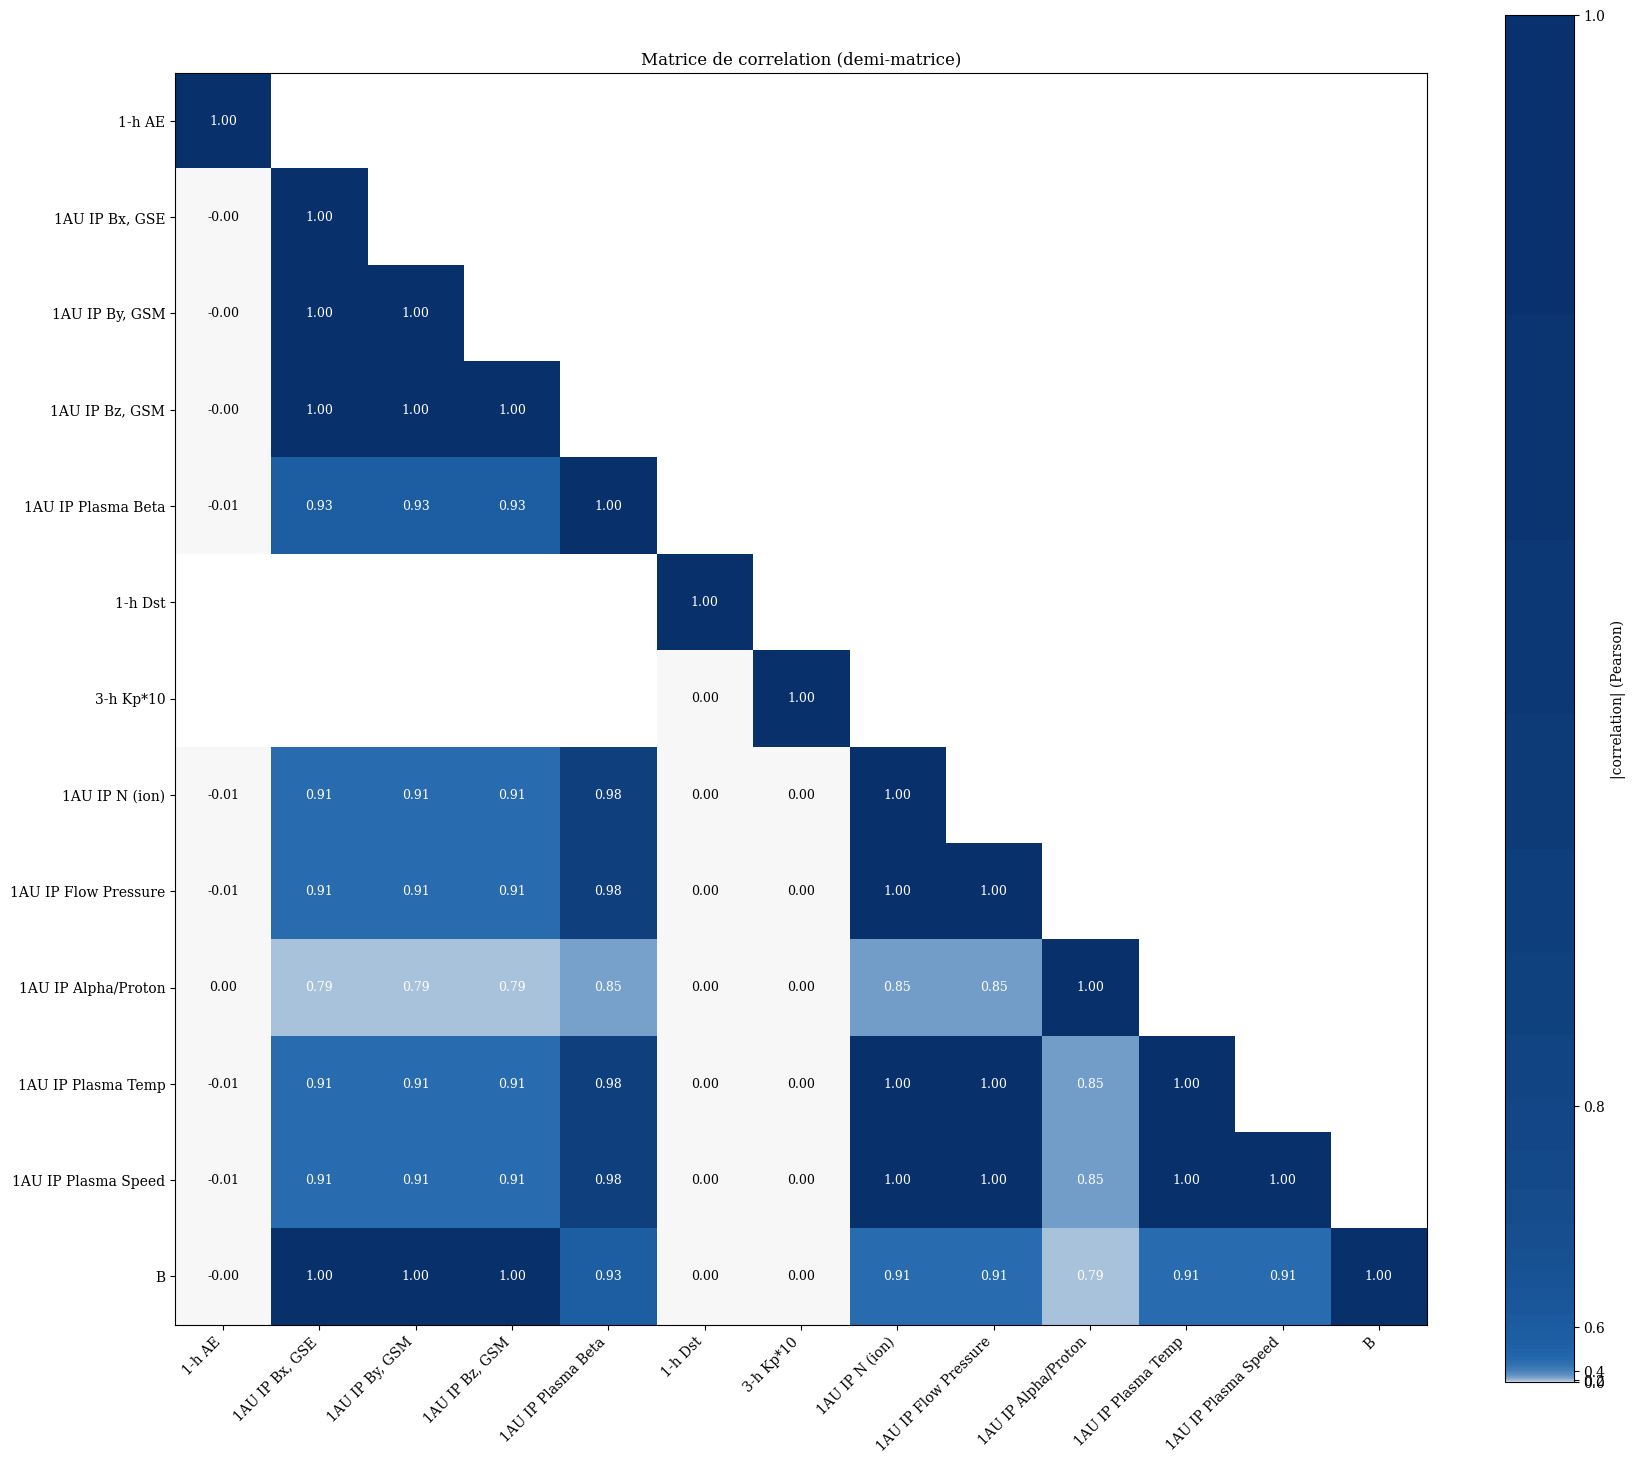

In [27]:
Mcorr_omni_speasycda2_1h_19840101_19951231 = matrice_correlation(M_omni_speasycda2_1h_19840101_19951231, log_scale=True)

### 1996-2007

Celle-ci ne nous intéresse pas trop car le nombre de données manquantes sur cette période est bien moindre que sur 1984-1995

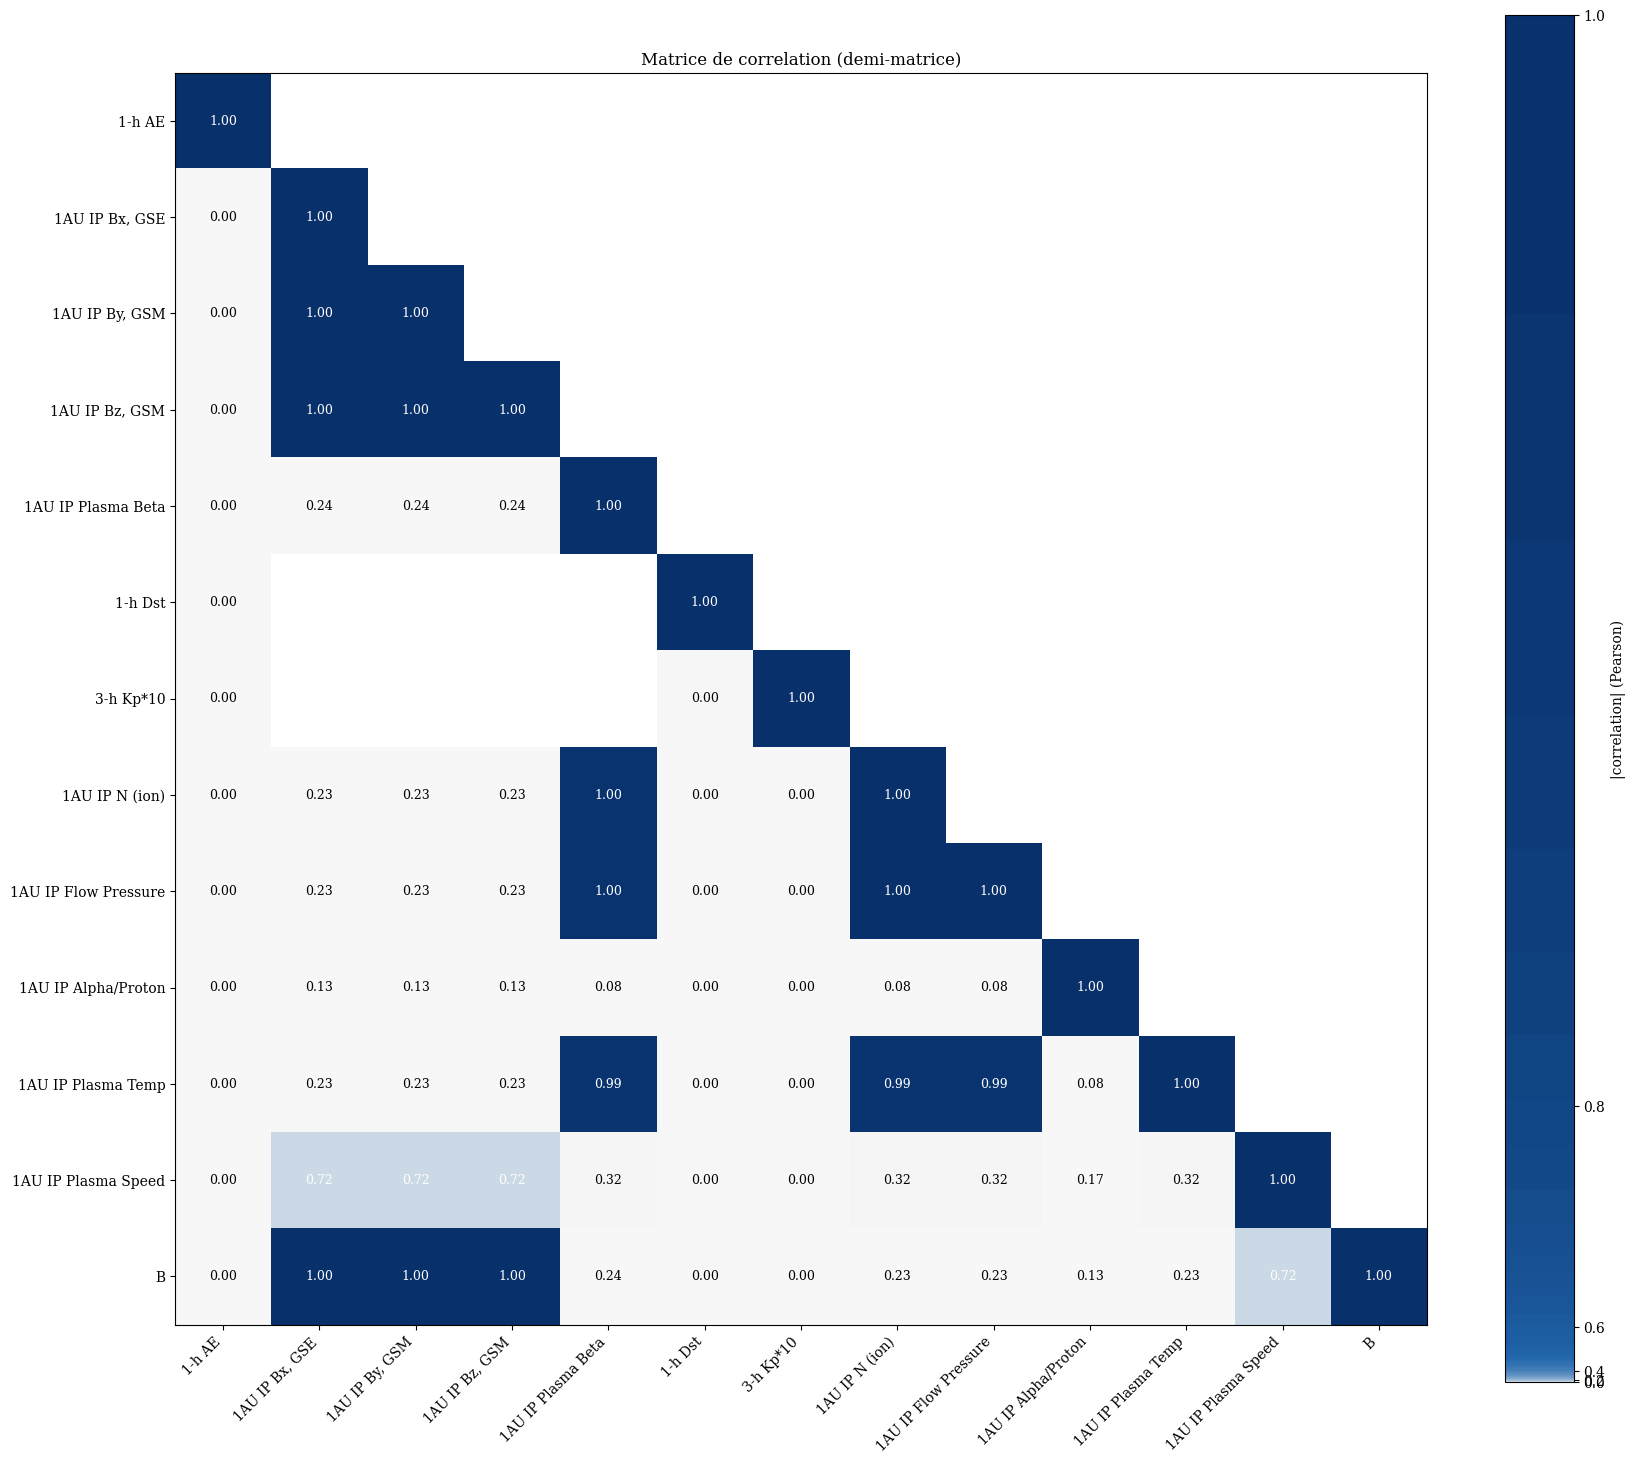

In [28]:
Mcorr_omni_speasycda2_1h_19960101_20071231 = matrice_correlation(M_omni_speasycda2_1h_19960101_20071231, log_scale=True)